### Loading the dataset


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_market_calendars as mcal

In [18]:
# Load historical META data
df = pd.read_csv(
    "../data/raw/META_5min.csv",
    parse_dates=["timestamp"]
)

df.head()

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,META,2025-10-31 13:30:00+00:00,674.56,674.890,660.50,662.5400,2819370.0,73589.0,668.882974
1,META,2025-10-31 13:35:00+00:00,662.51,666.000,661.27,661.8600,1211906.0,34987.0,663.475391
2,META,2025-10-31 13:40:00+00:00,661.81,662.000,660.00,660.6855,1599550.0,35593.0,660.923676
3,META,2025-10-31 13:45:00+00:00,660.58,663.000,657.14,657.9950,1448462.0,41710.0,660.342187
4,META,2025-10-31 13:50:00+00:00,657.93,658.062,654.27,656.5000,1768995.0,53447.0,655.714629


### Understanding the dataset

In [19]:
# Dataset dimension
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nData information:")
df.info()

# Statistical summary
df.describe()

Shape: (19506, 9)

Columns:
['symbol', 'timestamp', 'open', 'high', 'low', 'close', 'volume', 'trade_count', 'vwap']

Data information:
<class 'pandas.DataFrame'>
RangeIndex: 19506 entries, 0 to 19505
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   symbol       19506 non-null  str                
 1   timestamp    19506 non-null  datetime64[us, UTC]
 2   open         19506 non-null  float64            
 3   high         19506 non-null  float64            
 4   low          19506 non-null  float64            
 5   close        19506 non-null  float64            
 6   volume       19506 non-null  float64            
 7   trade_count  19506 non-null  float64            
 8   vwap         19506 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(7), str(1)
memory usage: 1.3 MB


,open,high,low,close,volume,trade_count,vwap
count,19506.000000,19506.000000,19506.000000,19506.000000,1.950600e+04,19506.000000,19506.000000
mean,633.967564,634.822820,633.095190,633.962118,1.847127e+05,5585.951246,633.967516
std,48.334394,48.403222,48.263361,48.335908,2.082006e+05,4954.508917,48.334056
min,521.080000,521.499900,520.260000,521.080000,2.166700e+04,1111.000000,520.959592
25%,600.908750,601.730000,600.060000,600.900000,7.995000e+04,2954.000000,600.945090
50%,632.010000,632.785000,631.050050,631.995000,1.226025e+05,4160.000000,631.925469
75%,663.000000,663.800000,662.250000,662.973750,2.084542e+05,6276.000000,662.960320
max,779.560000,779.819200,777.770000,779.620000,6.327773e+06,116705.000000,778.774097


### Checking missing values and duplicates


In [20]:
print("Missing values:")
display(df.isnull().sum())

print("duplicate timestamps:")
print(df["timestamp"].duplicated().sum())

Missing values:


symbol         0
timestamp      0
open           0
high           0
low            0
close          0
volume         0
trade_count    0
vwap           0
dtype: int64

duplicate timestamps:
0


### Validating OHLC data

In [21]:
invalid_ohlc = df[
    (df["high"] < df["low"]) |
    (df["high"] < df["open"]) |
    (df["high"] < df["close"]) |
    (df["low"] > df["open"]) |
    (df["low"] > df["close"])
]

print("Invalid OHLC rows:", len(invalid_ohlc))

print("Negative volume rows:", (df["volume"]<0).sum())

Invalid OHLC rows: 0
Negative volume rows: 0


### Analyze trading sessions

In [24]:
df["ny_timestamp"] = (
    df["timestamp"].dt.tz_convert("America/New_York")
)

df["trading_date"] = df["ny_timestamp"].dt.date

df["time"] = df["ny_timestamp"].dt.time

df.head()

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap,ny_timestamp,trading_date,time
0,META,2025-10-31 13:30:00+00:00,674.56,674.890,660.50,662.5400,2819370.0,73589.0,668.882974,2025-10-31 09:30:00-04:00,2025-10-31,09:30:00
1,META,2025-10-31 13:35:00+00:00,662.51,666.000,661.27,661.8600,1211906.0,34987.0,663.475391,2025-10-31 09:35:00-04:00,2025-10-31,09:35:00
2,META,2025-10-31 13:40:00+00:00,661.81,662.000,660.00,660.6855,1599550.0,35593.0,660.923676,2025-10-31 09:40:00-04:00,2025-10-31,09:40:00
3,META,2025-10-31 13:45:00+00:00,660.58,663.000,657.14,657.9950,1448462.0,41710.0,660.342187,2025-10-31 09:45:00-04:00,2025-10-31,09:45:00
4,META,2025-10-31 13:50:00+00:00,657.93,658.062,654.27,656.5000,1768995.0,53447.0,655.714629,2025-10-31 09:50:00-04:00,2025-10-31,09:50:00


In [26]:
daily_counts = df.groupby("trading_date").size()

print("Total candles:", len(df))
print("Trading days:", len(daily_counts))

print("\nDaily candle count:")
print(daily_counts.describe())

print("\nDuplicate timestamps:",
      df["timestamp"].duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())
print("\nMinimum candles:", daily_counts.min())
print("Maximum candles:", daily_counts.max())

daily_counts.describe()

Total candles: 19506
Trading days: 251

Daily candle count:
count    251.000000
mean      77.713147
std        3.207084
min       42.000000
25%       78.000000
50%       78.000000
75%       78.000000
max       78.000000
dtype: float64

Duplicate timestamps: 0

Missing values:
symbol          0
timestamp       0
open            0
high            0
low             0
close           0
volume          0
trade_count     0
vwap            0
ny_timestamp    0
trading_date    0
time            0
dtype: int64

Minimum candles: 42
Maximum candles: 78


count    251.000000
mean      77.713147
std        3.207084
min       42.000000
25%       78.000000
50%       78.000000
75%       78.000000
max       78.000000
dtype: float64

### Visualizing META's closing price

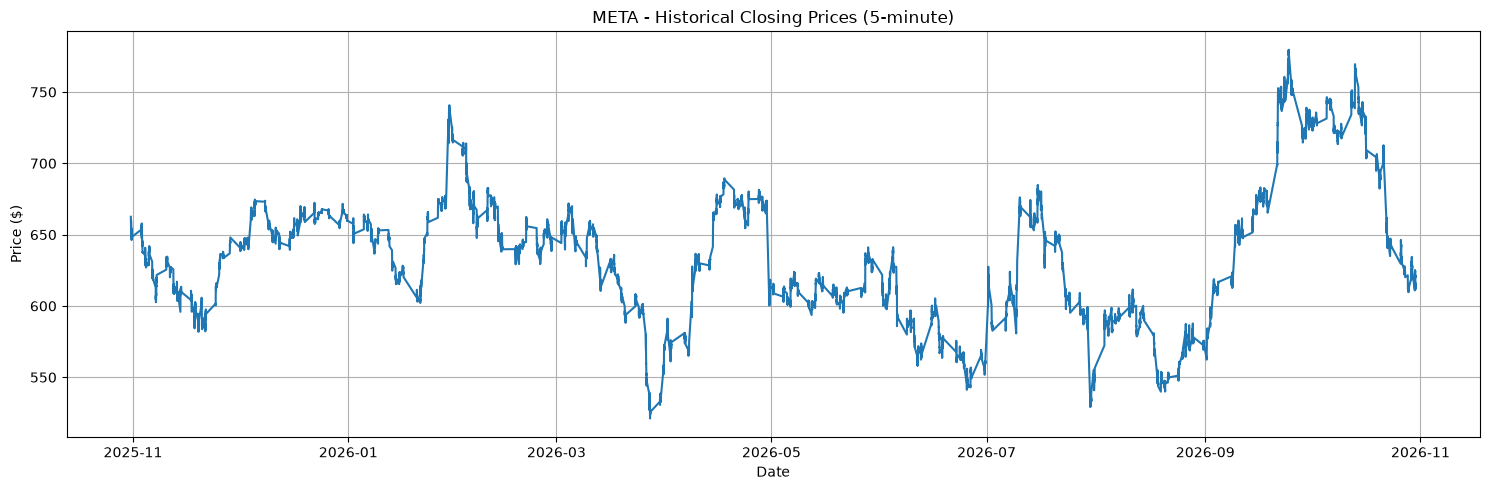

In [27]:
plt.figure(figsize=(15,5))

plt.plot(df["ny_timestamp"], df["close"])

plt.title("META - Historical Closing Prices (5-minute)")
plt.xlabel("Date")
plt.ylabel("Price ($)")

plt.grid(True)
plt.tight_layout()
plt.show()

### Visualizing trading volume

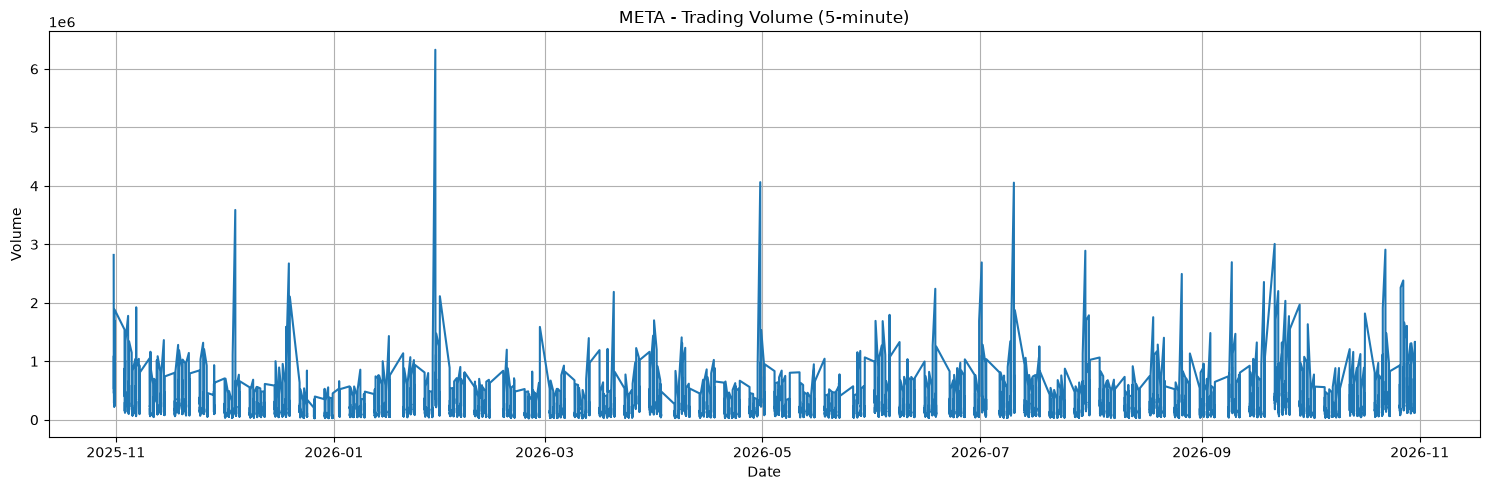

In [28]:
plt.figure(figsize=(15,5))

plt.plot(df["ny_timestamp"], df["volume"])

plt.title("META - Trading Volume (5-minute)")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.grid(True)
plt.tight_layout()
plt.show()

### Investigating missing intervals

In [29]:
df = df.sort_values("timestamp").copy()

df["time_difference"] = (
    df.groupby("trading_date")["timestamp"].diff()
)

gaps = df[
    df["time_difference"] > pd.Timedelta(minutes=5)
]

print("Intervals greater than 5 minutes:", len(gaps))

display(
    gaps[["ny_timestamp", "time_difference"]].head(20)
)

Intervals greater than 5 minutes: 0


,ny_timestamp,time_difference


In [30]:
short_days = daily_counts[daily_counts < 78]

print("Days with fewer than 78 candles:")
display(short_days)

Days with fewer than 78 candles:


trading_date
2025-11-28    42
2025-12-24    42
dtype: int64

Nov 28, 2025 is Day after Thanksgiving <br>
Dec 24, 2025 is Christmas Eve